In [2]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 32.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 12.6 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281396 sha256=0b26b1bfb6d8642338743c542f131a052d919b92f980204a52b950b9834a9467
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


Rozmiar macierzy: 128 x 128
CPU: 0.00019 s
CuPy: 0.00009 s
PyCUDA: 0.00063 s

Rozmiar macierzy: 256 x 256
CPU: 0.00051 s
CuPy: 0.00016 s
PyCUDA: 0.00018 s

Rozmiar macierzy: 512 x 512
CPU: 0.00266 s
CuPy: 0.00020 s
PyCUDA: 0.00097 s

Rozmiar macierzy: 1024 x 1024
CPU: 0.03470 s
CuPy: 0.00092 s
PyCUDA: 0.00683 s

Rozmiar macierzy: 2048 x 2048
CPU: 0.13886 s
CuPy: 0.00615 s
PyCUDA: 0.05371 s



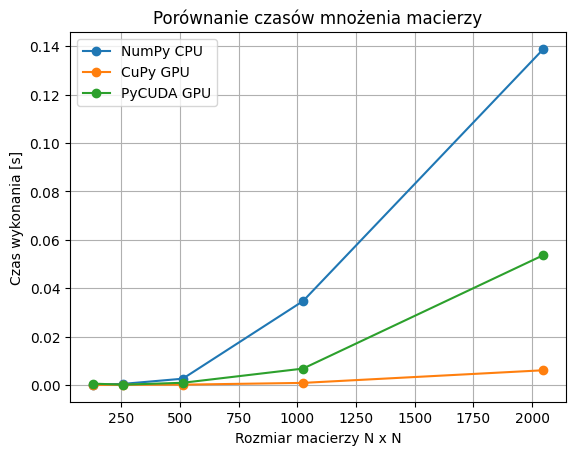

N	CPU [s]		CuPy [s]	PyCUDA [s]
128	0.00019		0.00009		0.00063
256	0.00051		0.00016		0.00018
512	0.00266		0.00020		0.00097
1024	0.03470		0.00092		0.00683
2048	0.13886		0.00615		0.05371


In [4]:

import numpy as np
import cupy as cp
import pycuda.driver as cuda
import pycuda.autoprimaryctx
from pycuda.compiler import SourceModule
import matplotlib.pyplot as plt
import time


kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    float sum = 0.0;

    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

rozmiary = [128, 256, 512, 1024, 2048]

czasy_cpu = []
czasy_cupy = []
czasy_pycuda = []

for N in rozmiary:
    print(f"Rozmiar macierzy: {N} x {N}")

    A_cpu = np.random.rand(N, N).astype(np.float32)
    B_cpu = np.random.rand(N, N).astype(np.float32)

    # NumPy - CPU
    start = time.time()
    C_cpu = np.matmul(A_cpu, B_cpu)
    end = time.time()
    czasy_cpu.append(end - start)

    # CuPy - GPU
    A_cp = cp.array(A_cpu)
    B_cp = cp.array(B_cpu)

    cp.matmul(A_cp, B_cp)
    cp.cuda.Stream.null.synchronize()

    start = time.time()
    C_cp = cp.matmul(A_cp, B_cp)
    cp.cuda.Stream.null.synchronize()
    end = time.time()
    czasy_cupy.append(end - start)

    # PyCUDA - GPU
    C_pycuda = np.empty((N, N), np.float32)

    A_gpu = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu = cuda.mem_alloc(C_pycuda.nbytes)

    cuda.memcpy_htod(A_gpu, A_cpu)
    cuda.memcpy_htod(B_gpu, B_cpu)

    block_size = (32, 32, 1)
    grid_size = ((N + 31) // 32, (N + 31) // 32, 1)

    start = time.time()
    matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N),
              block=block_size, grid=grid_size)
    cuda.Context.synchronize()
    end = time.time()

    czasy_pycuda.append(end - start)

    cuda.memcpy_dtoh(C_pycuda, C_gpu)

    del A_gpu, B_gpu, C_gpu

    print(f"CPU: {czasy_cpu[-1]:.5f} s")
    print(f"CuPy: {czasy_cupy[-1]:.5f} s")
    print(f"PyCUDA: {czasy_pycuda[-1]:.5f} s")
    print()

plt.plot(rozmiary, czasy_cpu, marker="o", label="NumPy CPU")
plt.plot(rozmiary, czasy_cupy, marker="o", label="CuPy GPU")
plt.plot(rozmiary, czasy_pycuda, marker="o", label="PyCUDA GPU")

plt.xlabel("Rozmiar macierzy N x N")
plt.ylabel("Czas wykonania [s]")
plt.title("Porównanie czasów mnożenia macierzy")
plt.legend()
plt.grid(True)
plt.show()

print("N\tCPU [s]\t\tCuPy [s]\tPyCUDA [s]")

for i in range(len(rozmiary)):
    print(f"{rozmiary[i]}\t{czasy_cpu[i]:.5f}\t\t{czasy_cupy[i]:.5f}\t\t{czasy_pycuda[i]:.5f}")
